# Baseline Model Comparison: Random Forest vs XGBoost vs LightGBM

Goal: see how far tabular models get on the features from the preprocessing notebook.
Inputs: `processed/{train,val,test}_tree.parquet`, `feature_sets.json`, `class_info.json` (from `preprocessing.ipynb`).

Model choices use validation only. The test split is used only to report results. `aux_*` and `strat_*` columns are never features.

## 1. Configuration

In [7]:
import json
import time
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             brier_score_loss, matthews_corrcoef, balanced_accuracy_score)
from sklearn.model_selection import ParameterSampler
from sklearn.calibration import calibration_curve
import xgboost as xgb
import lightgbm as lgb

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

PROC_DIR = "processed"
RES_DIR = "results"
os.makedirs(RES_DIR, exist_ok=True)

SEED = 42
FEATURE_SET = "FS_B"                 # main comparison; FS_A and FS_C are compared in the ablation
N_JOBS = -1
RF_MAX_TRAIN_ROWS = 400000
USE_CLASS_WEIGHTS = True
THRESHOLD_BETA = 2.0                 # F-beta used to pick the threshold on validation (2 = recall counts 4x precision)
TUNE = False                         # True: small random search per model on validation (slower)
N_TUNE_ITER = 10
K_LIST = (1, 3, 5, 10)
N_BOOT = 100

print("xgboost", xgb.__version__, "| lightgbm", lgb.__version__)

xgboost 3.4.0 | lightgbm 4.7.0


## 2. Load data

Reads the preprocessing outputs and checks that the splits share no case and no forbidden column is a feature.

In [8]:
def read_table(name):
    parquet_path = PROC_DIR + "/" + name + ".parquet"
    if os.path.exists(parquet_path):
        return pd.read_parquet(parquet_path)
    return pd.read_csv(PROC_DIR + "/" + name + ".csv.gz")


tr = read_table("train_tree")
va = read_table("val_tree")
te = read_table("test_tree")

fs = json.load(open(PROC_DIR + "/feature_sets.json"))
class_info = json.load(open(PROC_DIR + "/class_info.json"))
TARGET = fs["target"]
FEATS = fs[FEATURE_SET]

assert set(tr["case_id"]).isdisjoint(set(va["case_id"]))
assert set(tr["case_id"]).isdisjoint(set(te["case_id"]))
assert set(va["case_id"]).isdisjoint(set(te["case_id"]))

not_allowed = [TARGET, "case_id", "step", "agent_id", "ts_id"]
for name in ["FS_A", "FS_B", "FS_C"]:
    for c in fs[name]:
        assert not c.startswith("aux_") and not c.startswith("strat_"), c
        assert c not in not_allowed, c
        assert c in tr.columns, c

summary = pd.DataFrame({
    "rows": [len(tr), len(va), len(te)],
    "cases": [tr["case_id"].nunique(), va["case_id"].nunique(), te["case_id"].nunique()],
    "snapshots": [tr["ts_id"].nunique(), va["ts_id"].nunique(), te["ts_id"].nunique()],
    "critical_share": [tr[TARGET].mean(), va[TARGET].mean(), te[TARGET].mean()],
}, index=["train", "val", "test"])
display(summary)
print(FEATURE_SET, ":", len(FEATS), "features")

if USE_CLASS_WEIGHTS:
    scale_pos_weight = class_info["train_class_weights"]["scale_pos_weight"]
else:
    scale_pos_weight = 1.0
print("scale_pos_weight =", round(scale_pos_weight, 3))


def case_balanced_sample(d, max_rows, seed):
    """Takes the same fraction of rows from every case, so that all cases stay represented."""
    if len(d) <= max_rows:
        return d
    frac = max_rows / len(d)
    parts = []
    for case_id, rows_of_case in d.groupby("case_id"):
        parts.append(rows_of_case.sample(frac=frac, random_state=seed))
    return pd.concat(parts)


tr_rf = case_balanced_sample(tr, RF_MAX_TRAIN_ROWS, SEED)
print("random forest training rows:", len(tr_rf), "of", len(tr))

,rows,cases,snapshots,critical_share
train,998064,60,22691,0.3833
val,313396,20,7279,0.3834
test,327706,20,7761,0.4137


FS_B : 45 features
scale_pos_weight = 1.609
random forest training rows: 400000 of 998064


## 3. Metric functions

- **Classification:** PR-AUC is the main metric. Precision, recall, F1, F2, MCC, balanced accuracy and Brier score are reported at a threshold.
- **Ranking (per snapshot):** Precision@K, Recall@K, R-precision (K = number of critical agents), mean average precision and top-1 hit rate. Ties are broken at random.

In [9]:
def fbeta(precision, recall, beta):
    return (1 + beta ** 2) * precision * recall / max(beta ** 2 * precision + recall, 1e-12)


def best_threshold(y, p, beta=THRESHOLD_BETA):
    """Threshold with the highest F-beta score."""
    precision, recall, thresholds = precision_recall_curve(y, p)
    precision = precision[:-1]
    recall = recall[:-1]
    f = (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall + 1e-12)
    return float(thresholds[int(np.argmax(f))])


def clf_metrics(y, p, thr):
    """Classification metrics for scores p at threshold thr."""
    y = np.asarray(y)
    p = np.asarray(p)
    pred = (p >= thr).astype(int)

    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    precision = tp / max(tp + fp, 1)
    recall = tp / max(tp + fn, 1)

    both_classes = len(np.unique(y)) == 2

    result = {}
    result["pr_auc"] = average_precision_score(y, p) if both_classes else np.nan
    result["roc_auc"] = roc_auc_score(y, p) if both_classes else np.nan
    result["precision"] = precision
    result["recall"] = recall
    result["f1"] = fbeta(precision, recall, 1)
    result["f2"] = fbeta(precision, recall, 2)
    result["specificity"] = tn / max(tn + fp, 1)
    result["mcc"] = matthews_corrcoef(y, pred) if both_classes else np.nan
    result["balanced_acc"] = balanced_accuracy_score(y, pred) if both_classes else np.nan
    result["brier"] = brier_score_loss(y, np.clip(p, 0, 1)) if both_classes else np.nan
    result["prevalence"] = y.mean()
    result["threshold"] = thr
    return result


def rank_metrics(ts_id, y, score, ks=K_LIST, seed=SEED):
    """Ranking metrics per snapshot, averaged over snapshots with at least one critical agent."""
    ts_id = np.asarray(ts_id)
    y = np.asarray(y).astype(int)
    score = np.asarray(score, dtype=float)

    tie = np.random.default_rng(seed).random(len(y))

    order = np.lexsort((tie, -score, ts_id))
    t = ts_id[order]
    yy = y[order]

    start = np.r_[0, np.flatnonzero(np.diff(t)) + 1]
    size = np.diff(np.r_[start, len(t)])

    rank = np.arange(len(t)) - np.repeat(start, size)

    n_pos = np.add.reduceat(yy, start)
    valid = n_pos > 0

    result = {}
    for K in ks:
        hits_in_top_k = np.add.reduceat(yy * (rank < K), start)
        result["P@" + str(K)] = float(np.mean((hits_in_top_k / np.minimum(K, size))[valid]))
        result["R@" + str(K)] = float(np.mean((hits_in_top_k / np.maximum(n_pos, 1))[valid]))

    hits_r = np.add.reduceat(yy * (rank < np.repeat(n_pos, size)), start)
    result["r_precision"] = float(np.mean((hits_r / np.maximum(n_pos, 1))[valid]))

    cum_hits = np.cumsum(yy)
    if len(start) > 1:
        hits_before_snapshot = np.r_[0, cum_hits[start[1:] - 1]]
    else:
        hits_before_snapshot = np.array([0])
    hits_so_far = cum_hits - np.repeat(hits_before_snapshot, size)
    precision_at_rank = hits_so_far / (rank + 1)
    ap = np.add.reduceat(precision_at_rank * yy, start) / np.maximum(n_pos, 1)
    result["map"] = float(np.mean(ap[valid]))

    result["top1_hit"] = float(np.mean(yy[start][valid]))
    result["n_snapshots"] = int(valid.sum())
    return result


# quick self-test on a toy example: two snapshots with 6 agents and 2 critical agents each
toy_ts = np.repeat([0, 1], 6)
toy_y = np.tile([1, 1, 0, 0, 0, 0], 2)
perfect = np.tile([6, 5, 4, 3, 2, 1], 2)
worst = np.tile([1, 2, 3, 4, 5, 6], 2)
assert abs(rank_metrics(toy_ts, toy_y, perfect)["r_precision"] - 1) < 1e-9
assert rank_metrics(toy_ts, toy_y, worst)["r_precision"] == 0
assert abs(rank_metrics(toy_ts, toy_y, perfect)["map"] - 1) < 1e-9
print("ranking metric self-test passed")

ranking metric self-test passed


## 4. Baselines

- **Random:** PR-AUC equals the share of critical rows.
- **Best single feature:** the training feature with the highest PR-AUC, used directly as a score.
- **`criticality_score` heuristic:** the dataset's own score. It is not a model input.

In [10]:
# PR-AUC of every feature used on its own (on a sample of the training rows)
sub_tr = tr.sample(n=min(200000, len(tr)), random_state=SEED)
y_sub = sub_tr[TARGET].to_numpy()

single_pr_auc = {}
single_sign = {}
for c in FEATS:
    x = sub_tr[c].to_numpy(float)
    if x.max() == x.min():
        continue
    auc = roc_auc_score(y_sub, x)
    if auc >= 0.5:
        sign = 1
    else:
        sign = -1               # a low value of this feature means "critical"
    single_pr_auc[c] = average_precision_score(y_sub, sign * x)
    single_sign[c] = sign

best_feat = max(single_pr_auc, key=single_pr_auc.get)
best_sign = single_sign[best_feat]
print("best single training feature:", best_feat, "| train PR-AUC", round(single_pr_auc[best_feat], 3), "| sign", best_sign)


def baseline_scores(d):
    return {"random": np.random.default_rng(SEED).random(len(d)),
            "single: " + best_feat: best_sign * d[best_feat].to_numpy(float),
            "heuristic: criticality_score": d["aux_criticality_score"].to_numpy(float)}

best single training feature: weighted_density_z | train PR-AUC 0.799 | sign 1


## 5. Train the models

Random Forest (balanced class weights), XGBoost and LightGBM (medium trees, row/column subsampling, early stopping on validation PR-AUC). `TUNE = True` runs a small random search first. The test split is never used here.

In [11]:
Xtr = tr[FEATS]
ytr = tr[TARGET].to_numpy()
Xva = va[FEATS]
yva = va[TARGET].to_numpy()
Xte = te[FEATS]
yte = te[TARGET].to_numpy()
Xtr_rf = tr_rf[FEATS]
ytr_rf = tr_rf[TARGET].to_numpy()


def make_rf(**changes):
    params = dict(n_estimators=300, max_depth=None, min_samples_leaf=20, max_features="sqrt",
                  n_jobs=N_JOBS, random_state=SEED)
    if USE_CLASS_WEIGHTS:
        params["class_weight"] = "balanced_subsample"
    params.update(changes)
    return RandomForestClassifier(**params)


def make_xgb(**changes):
    params = dict(n_estimators=2000, learning_rate=0.05, max_depth=7, min_child_weight=20, subsample=0.8,
                  colsample_bytree=0.8, reg_lambda=2.0, tree_method="hist", n_jobs=N_JOBS, random_state=SEED,
                  scale_pos_weight=scale_pos_weight, eval_metric="aucpr", early_stopping_rounds=50)
    params.update(changes)
    return xgb.XGBClassifier(**params)


def make_lgb(**changes):
    params = dict(n_estimators=2000, learning_rate=0.05, num_leaves=63, min_child_samples=100, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0, n_jobs=N_JOBS, random_state=SEED,
                  scale_pos_weight=scale_pos_weight, verbose=-1)
    params.update(changes)
    return lgb.LGBMClassifier(**params)


def fit_model(name, params, X_train, y_train, X_val=None, y_val=None):
    """Fits one model and returns (model, seconds). The boosters use X_val to stop early."""
    if X_val is None:
        X_val = Xva
        y_val = yva
    t0 = time.time()
    if name == "RandomForest":
        model = make_rf(**params).fit(X_train, y_train)
    elif name == "XGBoost":
        model = make_xgb(**params).fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    else:
        model = make_lgb(**params).fit(X_train, y_train, eval_set=[(X_val, y_val)], eval_metric="average_precision",
                                       callbacks=[lgb.early_stopping(50, verbose=False)])
    return model, time.time() - t0


def fit_default(name, params):
    """Fits a model on the standard training data (random forest: smaller sample, boosters: all rows)."""
    if name == "RandomForest":
        return fit_model(name, params, Xtr_rf, ytr_rf)
    return fit_model(name, params, Xtr, ytr)


def predict(model, X):
    return model.predict_proba(X)[:, 1]


# search spaces for TUNE = True
SPACES = {
    "RandomForest": {"max_depth": [12, 20, 30, None], "min_samples_leaf": [5, 20, 50, 100], "max_features": ["sqrt", 0.3, 0.5]},
    "XGBoost": {"max_depth": [4, 6, 8, 10], "learning_rate": [0.03, 0.05, 0.1], "min_child_weight": [5, 20, 50, 100],
                "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.8, 1.0], "reg_lambda": [1, 2, 10]},
    "LightGBM": {"num_leaves": [15, 31, 63, 127], "learning_rate": [0.03, 0.05, 0.1], "min_child_samples": [20, 100, 300],
                 "subsample": [0.6, 0.8, 1.0], "colsample_bytree": [0.5, 0.8, 1.0], "reg_lambda": [1, 2, 10]},
}
MODELS = ["RandomForest", "XGBoost", "LightGBM"]

best_params = {}
for name in MODELS:
    best_params[name] = {}

if TUNE:
    for name in MODELS:
        best_score = -1
        for params in ParameterSampler(SPACES[name], n_iter=N_TUNE_ITER, random_state=SEED):
            model, _ = fit_default(name, params)
            score = average_precision_score(yva, predict(model, Xva))
            if score > best_score:
                best_score = score
                best_params[name] = params
        print(name, ": best validation PR-AUC", round(best_score, 4), "with", best_params[name])

models = {}
fit_time = {}
for name in MODELS:
    models[name], fit_time[name] = fit_default(name, best_params[name])
    extra = ""
    if name == "XGBoost":
        extra = " (best iteration " + str(models[name].best_iteration) + ")"
    if name == "LightGBM":
        extra = " (best iteration " + str(models[name].best_iteration_) + ")"
    print(name, "trained in", round(fit_time[name], 1), "s", extra)

RandomForest trained in 107.9 s 
XGBoost trained in 30.1 s  (best iteration 468)
LightGBM trained in 13.9 s  (best iteration 242)


## 6. Scores, thresholds and validation results

The threshold is chosen on validation by maximising F2 (recall counts more) and is used from here on.

In [24]:
def operating_points(y, p):
    """Three possible thresholds chosen on the data (y, p)."""
    precision, recall, thresholds = precision_recall_curve(y, p)
    precision = precision[:-1]
    recall = recall[:-1]
    out = {}
    for label, beta in [("F2", 2.0), ("F1", 1.0)]:
        f = (1 + beta ** 2) * precision * recall / (beta ** 2 * precision + recall + 1e-12)
        out[label] = float(thresholds[int(np.argmax(f))])
    ok = recall >= 0.95
    if ok.any():
        out["recall>=0.95"] = float(thresholds[ok][np.argmax(precision[ok])])
    else:
        out["recall>=0.95"] = float(thresholds.min())
    return out


# scores of every model on train (sample), validation and test
scores = {"val": {}, "test": {}, "train": {}}
for name in MODELS:
    scores["val"][name] = predict(models[name], Xva)
    scores["test"][name] = predict(models[name], Xte)
    scores["train"][name] = predict(models[name], Xtr.iloc[::5])
ytr_s = ytr[::5]

for split, d in [("val", va), ("test", te)]:
    baselines = baseline_scores(d)
    for k in baselines:
        scores[split][k] = baselines[k]
scores["train"]["heuristic: criticality_score"] = tr["aux_criticality_score"].to_numpy(float)[::5]

ops = {}
for name in scores["val"]:
    ops[name] = operating_points(yva, scores["val"][name])
THR = {}
for name in ops:
    THR[name] = ops[name]["F2"]

val_rows = []
for name in scores["val"]:
    p = scores["val"][name]
    row = clf_metrics(yva, p, THR[name])
    row.update(rank_metrics(va["ts_id"].to_numpy(), yva, p))
    row["model"] = name
    val_rows.append(row)
val_tbl = pd.DataFrame(val_rows).set_index("model")

display(val_tbl[["pr_auc", "roc_auc", "precision", "recall", "f1", "f2", "mcc", "r_precision", "map", "top1_hit", "P@5", "R@5", "brier"]])
val_tbl.to_csv(RES_DIR + "/validation_metrics.csv")

,pr_auc,roc_auc,precision,recall,f1,f2,mcc,r_precision,map,top1_hit,P@5,R@5,brier
model,,,,,,,,,,,,,
RandomForest,0.9653,0.9714,0.7949,0.9416,0.8621,0.9081,0.7720,0.8954,0.9500,0.9890,0.9715,0.3822,0.0611
XGBoost,0.9760,0.9816,0.8223,0.9572,0.8847,0.9268,0.8104,0.9187,0.9618,0.9887,0.9763,0.3846,0.0466
LightGBM,0.9756,0.9811,0.8449,0.9494,0.8941,0.9265,0.8258,0.9154,0.9603,0.9876,0.9752,0.3840,0.0471
random,0.3816,0.4980,0.3834,1.0000,0.5543,0.7566,0.0020,0.3743,0.4326,0.3686,0.3726,0.1428,0.3343
single: weighted_density_z,0.7841,0.8599,0.5396,0.9212,0.6806,0.8071,0.4422,0.7382,0.8207,0.9011,0.8749,0.3331,0.1548
heuristic: criticality_score,0.9989,0.9993,0.9460,0.9985,0.9716,0.9876,0.9541,0.9980,0.9997,1.0000,1.0000,0.4024,0.0320


## 7. Test results with case-level uncertainty

The test split has only about 20 cases. Cases are resampled with replacement (`N_BOOT` times) to get 95% intervals and paired differences between models. The curves show precision-recall, ROC and calibration.

In [14]:
te_y = yte
ts_te = te["ts_id"].to_numpy()
cases_te = te["case_id"].to_numpy()
case_ids = np.unique(cases_te)

case_rows = {}
for c in case_ids:
    case_rows[c] = np.flatnonzero(cases_te == c)

# test metrics at the thresholds fixed on validation
test_rows = []
for name in scores["test"]:
    p = scores["test"][name]
    row = clf_metrics(te_y, p, THR[name])
    row.update(rank_metrics(ts_te, te_y, p))
    row["model"] = name
    test_rows.append(row)
test_tbl = pd.DataFrame(test_rows).set_index("model")
test_tbl.to_csv(RES_DIR + "/test_metrics.csv")


def boot_stats(idx, name):
    """PR-AUC, recall, precision and R-precision of one model on the resampled rows idx."""
    p = scores["test"][name][idx]
    y = te_y[idx]
    thr = THR[name]
    tp = ((p >= thr) & (y == 1)).sum()
    result = {}
    result["pr_auc"] = average_precision_score(y, p)
    result["recall"] = tp / max((y == 1).sum(), 1)
    result["precision"] = tp / max((p >= thr).sum(), 1)
    result["r_precision"] = rank_metrics(ts_te[idx], y, p)["r_precision"]
    return result


boot = {}
for name in scores["test"]:
    boot[name] = []
rb = np.random.default_rng(SEED)
for b in range(N_BOOT):
    drawn_cases = rb.choice(case_ids, size=len(case_ids), replace=True)
    idx = np.concatenate([case_rows[c] for c in drawn_cases])
    for name in scores["test"]:
        boot[name].append(boot_stats(idx, name))

boot_df = {}
for name in boot:
    boot_df[name] = pd.DataFrame(boot[name])

ci_rows = []
for name in boot_df:
    row = {"model": name}
    for m in ["pr_auc", "recall", "precision", "r_precision"]:
        row[m] = test_tbl.loc[name, m]
        row[m + "_lo"] = boot_df[name][m].quantile(0.025)
        row[m + "_hi"] = boot_df[name][m].quantile(0.975)
    ci_rows.append(row)
ci = pd.DataFrame(ci_rows).set_index("model")

ci_cols = []
for m in ["pr_auc", "recall", "precision", "r_precision"]:
    ci_cols = ci_cols + [m, m + "_lo", m + "_hi"]

print("TEST, thresholds fixed on validation; 95% case-bootstrap intervals (", N_BOOT, "draws over", len(case_ids), "cases ):")
display(ci[ci_cols])
display(test_tbl[["pr_auc", "roc_auc", "precision", "recall", "f1", "f2", "specificity", "mcc", "balanced_acc", "brier",
                  "P@1", "P@3", "P@5", "P@10", "R@5", "R@10", "r_precision", "map", "top1_hit"]])
ci.to_csv(RES_DIR + "/test_metrics_ci.csv")

# paired differences between the learned models
diff_rows = []
for a, b in [("XGBoost", "RandomForest"), ("LightGBM", "RandomForest"), ("LightGBM", "XGBoost")]:
    for m in ["pr_auc", "recall", "r_precision"]:
        d = boot_df[a][m].to_numpy() - boot_df[b][m].to_numpy()
        lo = np.quantile(d, 0.025)
        hi = np.quantile(d, 0.975)
        diff_rows.append({"comparison": a + " - " + b, "metric": m, "mean_diff": d.mean(), "lo": lo, "hi": hi,
                          "significant (CI excludes 0)": bool(lo > 0 or hi < 0)})
diff_df = pd.DataFrame(diff_rows)
display(diff_df)
diff_df.to_csv(RES_DIR + "/paired_differences.csv", index=False)

TEST, thresholds fixed on validation; 95% case-bootstrap intervals ( 100 draws over 20 cases ):


,pr_auc,pr_auc_lo,pr_auc_hi,recall,recall_lo,recall_hi,precision,precision_lo,precision_hi,r_precision,r_precision_lo,r_precision_hi
model,,,,,,,,,,,,
RandomForest,0.9781,0.9637,0.9862,0.9643,0.9456,0.9778,0.8331,0.7858,0.8599,0.9105,0.8894,0.9287
XGBoost,0.9866,0.9771,0.9930,0.9772,0.9629,0.9903,0.8671,0.8241,0.8920,0.9374,0.9182,0.9532
LightGBM,0.9862,0.9762,0.9925,0.9706,0.9530,0.9855,0.8826,0.8436,0.9056,0.9337,0.9137,0.9500
random,0.4135,0.3862,0.4405,1.0000,1.0000,1.0000,0.4137,0.3872,0.4404,0.4153,0.3869,0.4446
single: weighted_density_z,0.7928,0.7430,0.8213,0.9437,0.9279,0.9534,0.5935,0.5400,0.6371,0.7668,0.7260,0.7904
heuristic: criticality_score,0.9972,0.9954,0.9996,0.9783,0.9369,1.0000,0.9719,0.9498,0.9918,0.9994,0.9989,1.0000


,pr_auc,roc_auc,precision,recall,f1,f2,specificity,mcc,balanced_acc,brier,P@1,P@3,P@5,P@10,R@5,R@10,r_precision,map,top1_hit
model,,,,,,,,,,,,,,,,,,,
RandomForest,0.9781,0.9821,0.8331,0.9643,0.8939,0.9349,0.8637,0.8163,0.9140,0.0538,0.9823,0.9727,0.9617,0.8802,0.3876,0.6504,0.9105,0.9561,0.9823
XGBoost,0.9866,0.9896,0.8671,0.9772,0.9189,0.9530,0.8943,0.8604,0.9358,0.0368,0.9872,0.9803,0.9728,0.8922,0.3944,0.6625,0.9374,0.9714,0.9872
LightGBM,0.9862,0.9892,0.8826,0.9706,0.9245,0.9516,0.9089,0.8698,0.9397,0.0373,0.9872,0.9816,0.9712,0.8900,0.3932,0.6602,0.9337,0.9701,0.9872
random,0.4135,0.5007,0.4137,1.0000,0.5852,0.7791,0.0000,-0.0004,0.5000,0.3329,0.4123,0.4149,0.4136,0.4145,0.1652,0.3310,0.4153,0.4720,0.4123
single: weighted_density_z,0.7928,0.8731,0.5935,0.9437,0.7287,0.8441,0.5439,0.5061,0.7438,0.1513,0.8682,0.8737,0.8439,0.7750,0.3311,0.5634,0.7668,0.8347,0.8682
heuristic: criticality_score,0.9972,0.9981,0.9719,0.9783,0.9751,0.9770,0.9800,0.9574,0.9792,0.0586,1.0000,1.0000,1.0000,0.9065,0.4136,0.6768,0.9994,1.0000,1.0000


,comparison,metric,mean_diff,lo,hi,significant (CI excludes 0)
0,XGBoost - RandomForest,pr_auc,0.0090,0.0064,0.0135,True
1,XGBoost - RandomForest,recall,0.0134,0.0080,0.0214,True
2,XGBoost - RandomForest,r_precision,0.0273,0.0215,0.0321,True
3,LightGBM - RandomForest,pr_auc,0.0085,0.0059,0.0127,True
4,LightGBM - RandomForest,recall,0.0065,0.0012,0.0116,True
5,LightGBM - RandomForest,r_precision,0.0236,0.0185,0.0282,True
6,LightGBM - XGBoost,pr_auc,-0.0005,-0.0014,0.0003,False
7,LightGBM - XGBoost,recall,-0.0068,-0.0097,-0.0043,True
8,LightGBM - XGBoost,r_precision,-0.0037,-0.0051,-0.0027,True


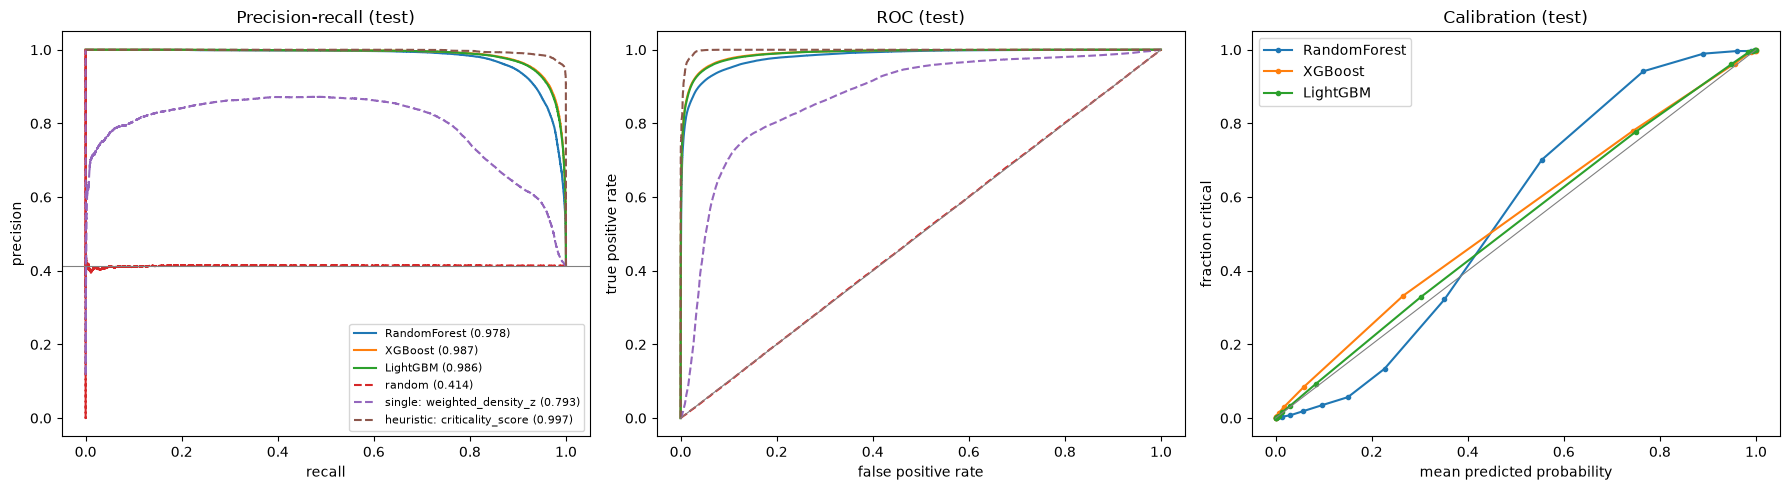

In [15]:
# precision-recall curve, ROC curve and calibration curve on the test split
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for name in scores["test"]:
    p = scores["test"][name]
    precision, recall, _ = precision_recall_curve(te_y, p)
    fpr, tpr, _ = roc_curve(te_y, p)
    if name in MODELS:
        line = "-"
    else:
        line = "--"

    axes[0].plot(recall, precision, line, label=name + " (" + str(round(average_precision_score(te_y, p), 3)) + ")")
    axes[1].plot(fpr, tpr, line, label=name)
    if name in MODELS:
        frac_critical, mean_pred = calibration_curve(te_y, np.clip(p, 0, 1), n_bins=15, strategy="quantile")
        axes[2].plot(mean_pred, frac_critical, marker="o", ms=3, label=name)

axes[0].axhline(te_y.mean(), color="grey", lw=0.8)
axes[0].set_xlabel("recall")
axes[0].set_ylabel("precision")
axes[0].set_title("Precision-recall (test)")
axes[0].legend(fontsize=8)

axes[1].plot([0, 1], [0, 1], color="grey", lw=0.8)
axes[1].set_xlabel("false positive rate")
axes[1].set_ylabel("true positive rate")
axes[1].set_title("ROC (test)")

axes[2].plot([0, 1], [0, 1], color="grey", lw=0.8)
axes[2].set_xlabel("mean predicted probability")
axes[2].set_ylabel("fraction critical")
axes[2].set_title("Calibration (test)")
axes[2].legend()
plt.tight_layout()
plt.show()

## 8. Ablation on the test split (FS_A vs FS_B vs FS_C)

Same model and hyperparameters for each feature set. The threshold is chosen on validation. Change `ABL_MODEL` to run it for another model.

In [21]:
ABL_MODEL = "LightGBM"

abl_rows = []
p_test_by_fs = {}
thr_by_fs = {}
for fs_name in ["FS_A", "FS_B", "FS_C"]:
    cols = fs[fs_name]
    model, fit_s = fit_model(ABL_MODEL, best_params[ABL_MODEL], tr[cols], ytr, va[cols], yva)

    p_val = predict(model, va[cols])
    thr = best_threshold(yva, p_val, beta=THRESHOLD_BETA)
    p_test = predict(model, te[cols])
    r = clf_metrics(yte, p_test, thr)
    rk = rank_metrics(ts_te, yte, p_test)
    best_iter = model.best_iteration_

    p_test_by_fs[fs_name] = p_test
    thr_by_fs[fs_name] = thr
    abl_rows.append({"feature_set": fs_name, "n_features": len(cols), "model": ABL_MODEL,
                     "test_pr_auc": r["pr_auc"], "test_roc_auc": r["roc_auc"],
                     "test_recall": r["recall"], "test_precision": r["precision"], "test_f2": r["f2"],
                     "test_r_precision": rk["r_precision"], "test_map": rk["map"],
                     "threshold_val": thr, "best_iter": best_iter, "fit_s": round(fit_s, 1)})

abl_test = pd.DataFrame(abl_rows).set_index("feature_set")
print("TEST ablation,", ABL_MODEL, "(threshold from validation, F" + str(THRESHOLD_BETA) + "):")
display(abl_test)
abl_test.to_csv(RES_DIR + "/ablation_test_" + ABL_MODEL + ".csv")

# sanity check: the FS_B row must match the headline numbers, because FEATURE_SET = "FS_B" in the main run
if ABL_MODEL in test_tbl.index and FEATURE_SET == "FS_B":
    print("headline", ABL_MODEL, "test PR-AUC", round(test_tbl.loc[ABL_MODEL, "pr_auc"], 4),
          "| FS_B row", round(abl_test.loc["FS_B", "test_pr_auc"], 4), "(should match)")

TEST ablation, LightGBM (threshold from validation, F2.0):


,n_features,model,test_pr_auc,test_roc_auc,test_recall,test_precision,test_f2,test_r_precision,test_map,threshold_val,best_iter,fit_s
feature_set,,,,,,,,,,,,
FS_A,29,LightGBM,0.9782,0.9835,0.9616,0.8609,0.9397,0.9244,0.9636,0.1925,436,18.1000
FS_B,45,LightGBM,0.9862,0.9892,0.9706,0.8826,0.9516,0.9337,0.9701,0.1842,242,14.3000
FS_C,51,LightGBM,0.9848,0.9881,0.9633,0.8858,0.9467,0.9335,0.9687,0.1780,288,17.0000


headline LightGBM test PR-AUC 0.9862 | FS_B row 0.9862 (should match)
